# Lab 3 — Cleaning HST Data: Measuring an Eclipse Depth

**ASTR3986: Astrostatistics**

The data are a *Hubble Space Telescope* light curve ({time, flux, error on flux}) that
contains eclipses from a companion object. HST's low-Earth orbit (period 95.48 minutes)
means the target is only visible for part of each orbit, so the data are sparse and come
in six separated "visits." On top of the eclipses themselves, the light curve is
contaminated by:

- photon noise (given by the reported error bars),
- a slow, roughly linear trend in time,
- a sinusoidal variation on an hours timescale (the star itself), and
- outliers caused by cosmic ray hits.

**Goal:** detrend the data and measure the depth of the eclipses (and its uncertainty).

We use a **parametric** detrending approach: a model consisting of a linear trend, a
sinusoid, and a box-shaped eclipse, fit simultaneously with an MCMC sampler so that the
uncertainty on the linear/sinusoidal nuisance parameters is correctly propagated into the
uncertainty on the eclipse depth. We cross-check the MCMC result against a simple
weighted-average depth measurement.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal

rng = np.random.default_rng(42)
%matplotlib inline

## Load the data and the known ephemeris

The header of `data_headers.dat` tells us the columns are `{time [days], flux [e-/s],
error on flux [e-/s]}`. From the lab handout we also know the eclipse ephemeris and the
HST orbital period:

- cadence of exposures = 13.2 s
- $P_\mathrm{HST}$ = 95.48 min
- duration of eclipses = 166.484 s
- central time of the first eclipse $t_0$ = 57531.91792371155 (BJD-ish time unit)
- period of the eclipses = 2.025026511149096 hours

1605 data points, 51 of them inside an eclipse window


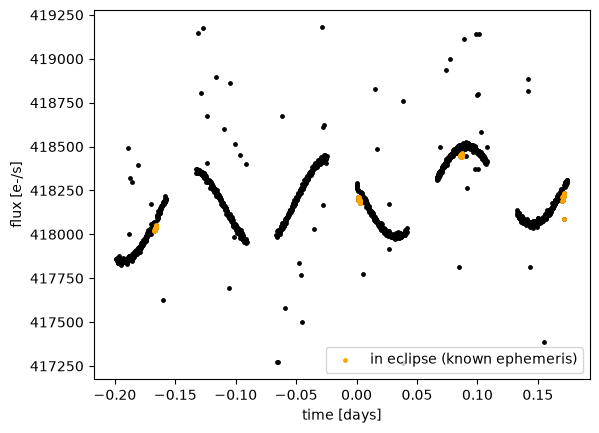

In [2]:
dataraw = np.loadtxt("data_headers.dat", skiprows=3).T  # columns: time, flux, fluxerr

tpivot = np.median(dataraw[0][:])          # pivot point, used to keep the time axis small
time = dataraw[0][:] - tpivot              # Time [d], relative to tpivot
flux = dataraw[1][:]                       # Flux [e-/s]
fluxerr = dataraw[2][:]                    # Error on flux [e-/s]

# Known information about the system
mins = 1.0 / (24.0 * 60.0)                 # one minute [days]
Phst = 95.48 * mins                        # period of HST [days]
dur = 166.484 / 86400.0                    # duration of the eclipse [days]
t0 = 57531.91792371155 - tpivot            # mid-time of first eclipse (pivot-shifted)
Ptran = 2.025026511149096 / 24.0           # period of eclipses [days]
cadence = 13.2 / 86400.0                   # cadence [days]

def in_eclipse(t, t0, P, dur):
    # Boolean mask: True for points that fall inside an eclipse window
    phase = ((t - t0 + P / 2.0) % P) - P / 2.0
    return np.abs(phase) < dur / 2.0

ecl = in_eclipse(time, t0, Ptran, dur)
print(f"{len(time)} data points, {ecl.sum()} of them inside an eclipse window")

plt.scatter(time, flux, color="k", s=6)
plt.scatter(time[ecl], flux[ecl], color="orange", s=6, label="in eclipse (known ephemeris)")
plt.xlabel("time [days]")
plt.ylabel("flux [e-/s]")
plt.legend()
plt.show()

## Task 1: Remove outliers

Cosmic rays produce sharp, one-point spikes in the light curve. We flag them with a
moving-median filter: smooth the flux with a median over a small window (`window = 11`
points, short enough not to wash out the hours-timescale sinusoid), then flag any point
whose residual from that smooth trend is more than `sigmas = 3` robust-sigma away.

4.98% of the original data are flagged as outliers


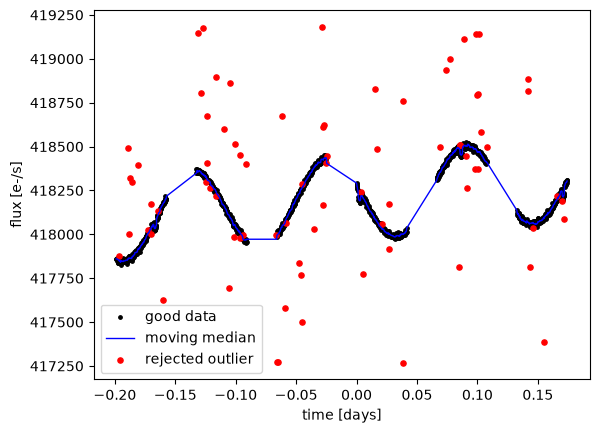

In [3]:
def moving_median(x, window):
    # Median-filter x with the given odd window size, holding the edges fixed
    n = len(x)
    half = window // 2
    out = np.empty(n)
    for i in range(n):
        lo = max(0, i - half)
        hi = min(n, i + half + 1)
        out[i] = np.median(x[lo:hi])
    return out

smoothwindow = 11
fluxsmooth = moving_median(flux, smoothwindow)

# Residuals from the smooth trend, and a robust (MAD-based) estimate of their scatter
resid = flux - fluxsmooth
mad = 1.4826 * np.median(np.abs(resid - np.median(resid)))

sigmas = 3
good = np.abs(resid) < sigmas * mad
bad = ~good

print(f"{100.0 * bad.sum() / len(flux):.2f}% of the original data are flagged as outliers")

plt.scatter(time[good], flux[good], color="k", s=6, label="good data")
plt.plot(time, fluxsmooth, color="b", lw=1, label="moving median")
plt.scatter(time[bad], flux[bad], color="r", s=14, label="rejected outlier")
plt.xlabel("time [days]")
plt.ylabel("flux [e-/s]")
plt.legend()
plt.show()

# Clean arrays used in everything that follows
time_c, flux_c, fluxerr_c, ecl_c = time[good], flux[good], fluxerr[good], ecl[good]

## Task 2: Find the period of the sinusoidal signal

Before fitting, we get a good starting guess for the stellar sinusoid's period and
amplitude. We mask out the (known) eclipse windows so they don't bias the periodogram,
remove a linear trend, and run a Lomb-Scargle periodogram on what's left.

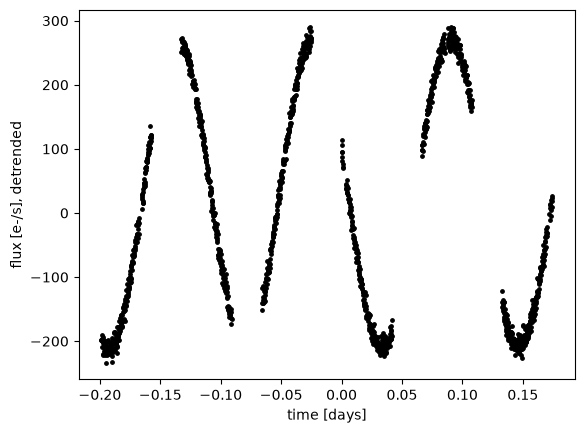

In [4]:
oot = ~ecl_c  # "out of transit/eclipse" mask

# Task 2b: remove a linear trend before passing the data through the periodogram
tempslope = np.polyfit(time_c[oot], flux_c[oot], 1)
periodogramdata = flux_c[oot] - np.polyval(tempslope, time_c[oot])

plt.scatter(time_c[oot], periodogramdata, color="k", s=6)
plt.xlabel("time [days]")
plt.ylabel("flux [e-/s], detrended")
plt.show()

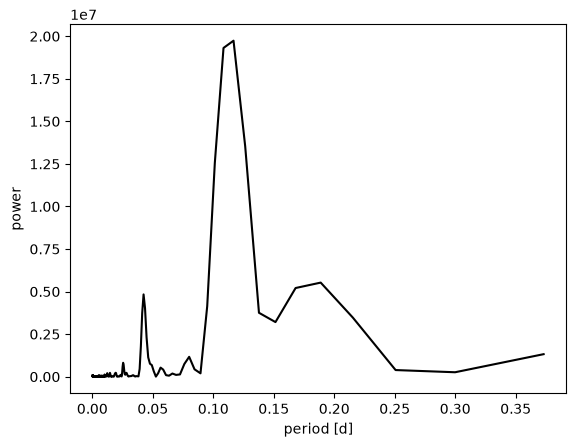

best period = 0.11672 d  (2.801 hr)
best amp    = 231.280 e-/s


In [5]:
# Task 2c: run a Lomb-Scargle periodogram through it
nfreq = 5000
freqmax = np.pi / cadence
freqmin = 2.0 * np.pi / (time_c.max() - time_c.min())
freqs = np.linspace(freqmin, freqmax, nfreq)
periods = 2.0 * np.pi / freqs

pgram = signal.lombscargle(time_c[oot], periodogramdata, freqs, precenter=True)
Pbest = periods[np.argmax(pgram)]
# periodogram has a peak at (A**2) * N/4, per the scipy documentation, so:
Abest = np.sqrt(4.0 * pgram[np.argmax(pgram)] / oot.sum())

plt.plot(periods, pgram, color="k")
plt.xlabel("period [d]")
plt.ylabel("power")
plt.show()

print(f"best period = {Pbest:.5f} d  ({Pbest * 24:.3f} hr)")
print(f"best amp    = {Abest:.3f} e-/s")

## Task 3: Remove the sinusoid + trend (+ eclipse) together, with uncertainty propagation

We now fit **all** of the systematics and the eclipse simultaneously:

$$f(t) = \big[a_0 + a_1\,t + A\sin(2\pi t/P + \phi)\big] \times \big(1 - d\cdot\mathbb{1}_\mathrm{eclipse}(t)\big)$$

where $d$ is the fractional eclipse depth we want to measure, and
$\mathbb{1}_\mathrm{eclipse}(t)$ is 1 inside an eclipse window (using the known ephemeris)
and 0 otherwise. Fitting everything together, rather than detrending first and measuring
the depth second, means the MCMC posterior on $d$ automatically includes the uncertainty
contributed by the trend and sinusoid parameters (Task 4a).

In [6]:
def model(t, theta, ecl_mask):
    a0, a1, A, P, phi, depth = theta
    baseline = a0 + a1 * t + A * np.sin(2.0 * np.pi * t / P + phi)
    return baseline * (1.0 - depth * ecl_mask)

def log_like(theta, t, f, ferr, ecl_mask):
    # Log-likelihood assuming normally distributed data
    m = model(t, theta, ecl_mask)
    return -0.5 * np.sum(((f - m) / ferr) ** 2 + np.log(2.0 * np.pi * ferr ** 2))

# Set an initial chain point, seeded from a "reasonable" solution
a0_0 = np.median(flux_c)
a1_0 = tempslope[0]

phi_grid = np.linspace(0, 2 * np.pi, 400)
chi2_grid = [np.sum((flux_c - (a0_0 + a1_0 * time_c + Abest * np.sin(2 * np.pi * time_c / Pbest + p))) ** 2)
             for p in phi_grid]
phi0 = phi_grid[np.argmin(chi2_grid)]

theta0 = np.array([a0_0, a1_0, Abest, Pbest, phi0, 1.0e-3])
print("theta0 (a0, a1, A, P, phi, depth):", theta0)
print("initial log-likelihood:", log_like(theta0, time_c, flux_c, fluxerr_c, ecl_c))

theta0 (a0, a1, A, P, phi, depth): [4.18139799e+05 6.08259491e+02 2.31279711e+02 1.16718417e-01
 2.85026702e+00 1.00000000e-03]
initial log-likelihood: -118319.7209823312


In [7]:
def run_chain(theta_start, jump, nsteps, t, f, ferr, ecl_mask, rng):
    # A simple Metropolis-Hastings sampler with independent Gaussian proposals
    ndim = len(theta_start)
    chain = np.empty((nsteps, ndim))
    loglikechain = np.empty(nsteps)

    theta = theta_start.copy()
    ll = log_like(theta, t, f, ferr, ecl_mask)
    naccept = 0

    for j in range(nsteps):
        # Generate a proposal (or jump)
        proposal = theta + jump * rng.normal(size=ndim)
        llp = log_like(proposal, t, f, ferr, ecl_mask)

        # Compute Metropolis rule
        if np.log(rng.uniform()) < (llp - ll):
            theta, ll = proposal, llp
            naccept += 1

        chain[j] = theta
        loglikechain[j] = ll

    return chain, loglikechain, naccept / nsteps

# Define the proposal jump size: start conservative, based on the flux errors
a0jump = 0.1 * np.median(fluxerr_c)
a1jump = 0.1 * np.median(fluxerr_c) / (time_c.max() - time_c.min())
Ajump = 0.1 * np.median(fluxerr_c)
Pjump = 0.1 * Pbest / 1000.0
phijump = 0.05
depthjump = 0.1 * np.median(fluxerr_c) / a0_0
thetajump = np.array([a0jump, a1jump, Ajump, Pjump, phijump, depthjump])

short run acceptance fraction = 0.197


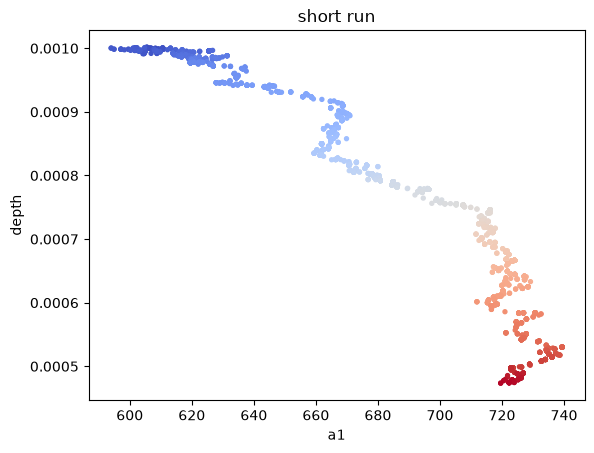

In [8]:
# short run
chain_short, ll_short, acc_short = run_chain(
    theta0, thetajump, 2000, time_c, flux_c, fluxerr_c, ecl_c, rng)
print(f"short run acceptance fraction = {acc_short:.3f}")

plt.scatter(chain_short[:, 1], chain_short[:, 5], c=np.arange(len(chain_short)), cmap="coolwarm", s=8)
plt.xlabel("a1")
plt.ylabel("depth")
plt.title("short run")
plt.show()

stdev of 2nd half of short chain: [2.55137517e+00 2.45750061e+01 2.70309657e+00 2.82765943e-04
 1.16510166e-02 1.24758728e-04]
jump sizes used:                  [8.86438800e-01 2.37598070e+00 8.86438800e-01 1.16718417e-05
 5.00000000e-02 2.11995797e-06]


medium run acceptance fraction = 0.005


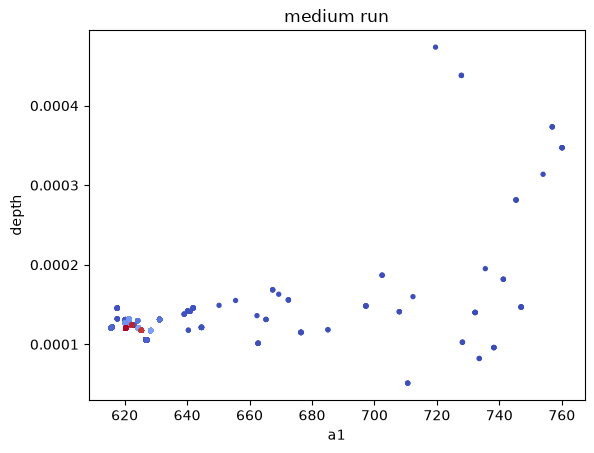

In [9]:
# Check how the jump sizes compare to the scatter of the second half of the chain,
# and re-tune the jump sizes before the next, longer run
stdevs = np.std(chain_short[500:], axis=0)
print("stdev of 2nd half of short chain:", stdevs)
print("jump sizes used:                 ", thetajump)

thetajump_medium = 0.5 * stdevs
chain_medium, ll_medium, acc_medium = run_chain(
    chain_short[-1], thetajump_medium, 10000, time_c, flux_c, fluxerr_c, ecl_c, rng)
print(f"medium run acceptance fraction = {acc_medium:.3f}")

plt.scatter(chain_medium[:, 1], chain_medium[:, 5], c=np.arange(len(chain_medium)), cmap="coolwarm", s=8)
plt.xlabel("a1")
plt.ylabel("depth")
plt.title("medium run")
plt.show()

long run acceptance fraction = 0.813


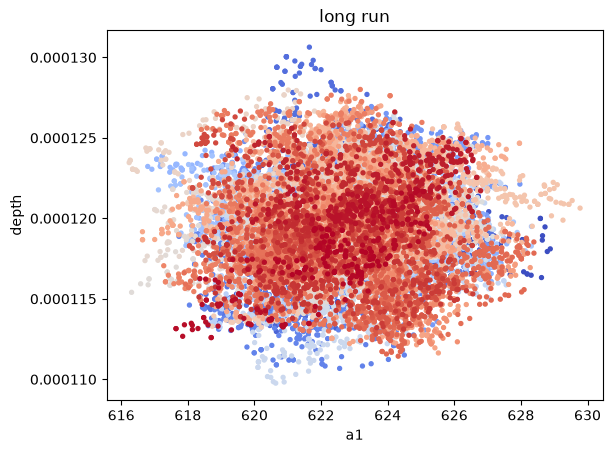

In [10]:
# Re-tune once more and run the long chain
stdevs_medium = np.std(chain_medium[2000:], axis=0)
thetajump_long = 0.4 * stdevs_medium

chain_long, ll_long, acc_long = run_chain(
    chain_medium[-1], thetajump_long, 20000, time_c, flux_c, fluxerr_c, ecl_c, rng)
print(f"long run acceptance fraction = {acc_long:.3f}")

plt.scatter(chain_long[:, 1], chain_long[:, 5], c=np.arange(len(chain_long)), cmap="coolwarm", s=8)
plt.xlabel("a1")
plt.ylabel("depth")
plt.title("long run")
plt.show()

burn point = 17


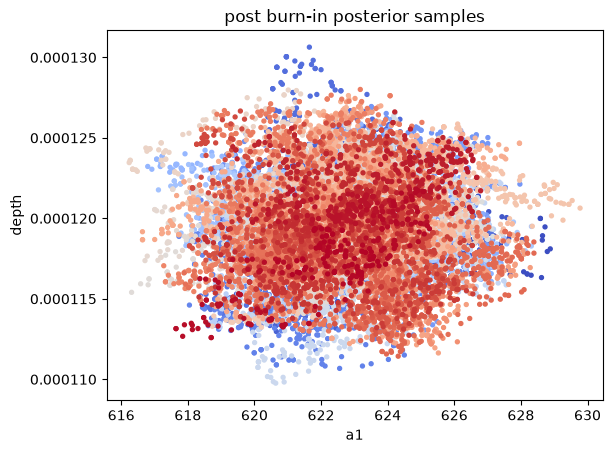

In [11]:
# Burn in: discard the chain up to the point where the log-likelihood first
# exceeds the median log-likelihood of the whole chain
loglikeburn = np.median(ll_long)
burnj = np.argmax(ll_long > loglikeburn)
print("burn point =", burnj)

thetachain = chain_long[burnj:, :]
loglikechain = ll_long[burnj:]

plt.scatter(thetachain[:, 1], thetachain[:, 5], c=np.arange(len(thetachain)), cmap="coolwarm", s=8)
plt.xlabel("a1")
plt.ylabel("depth")
plt.title("post burn-in posterior samples")
plt.show()

### Task 4a: propagate the detrending uncertainty into the depth estimate

Because the trend, sinusoid and eclipse were all fit together, the posterior distribution
of the `depth` column of the MCMC chain already has the uncertainty from the other
parameters folded in. We summarize it with its median and standard deviation.

best-fit parameters (a0, a1, A, P, phi, depth):
[4.18209499e+05 6.21955735e+02 2.41035674e+02 1.13145960e-01
 2.86723005e+00 1.19263157e-04]

MCMC eclipse depth = 0.000120 +/- 0.000003  (119.5 +/- 3.0 ppm)


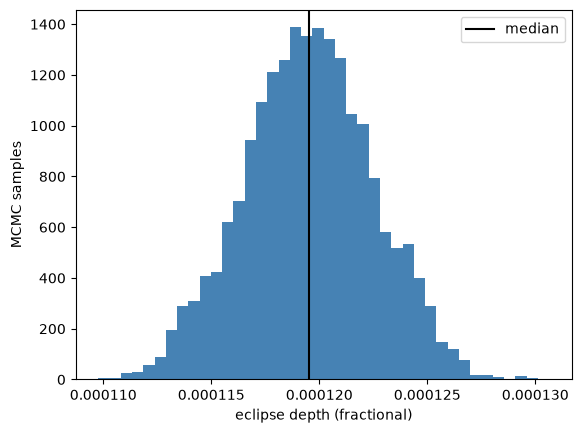

In [12]:
theta_best = thetachain[np.argmax(loglikechain), :]
print("best-fit parameters (a0, a1, A, P, phi, depth):")
print(theta_best)

depth_chain = thetachain[:, 5]
depth_mcmc = np.median(depth_chain)
depth_mcmc_err = np.std(depth_chain)

print(f"\nMCMC eclipse depth = {depth_mcmc:.6f} +/- {depth_mcmc_err:.6f}"
      f"  ({depth_mcmc * 1e6:.1f} +/- {depth_mcmc_err * 1e6:.1f} ppm)")

plt.hist(depth_chain, bins=40, color="steelblue")
plt.axvline(depth_mcmc, color="k", label="median")
plt.xlabel("eclipse depth (fractional)")
plt.ylabel("MCMC samples")
plt.legend()
plt.show()

## Task 3 cross-check: depth from a weighted average

As a cross-check of the MCMC result, we take the best-fit *continuum* model (trend +
sinusoid, with the eclipse switched off), compute the fractional residual of each in-eclipse
point below that continuum, and combine them into a single depth estimate with an
inverse-variance (weighted-average) estimator.

In [13]:
theta_noecl = theta_best.copy()
theta_noecl[5] = 0.0
continuum = model(time_c, theta_noecl, np.zeros_like(ecl_c, dtype=float))

frac_resid = (continuum - flux_c) / continuum
sigma_frac = fluxerr_c / continuum
weights = 1.0 / sigma_frac**2

depth_wavg = np.sum(weights[ecl_c] * frac_resid[ecl_c]) / np.sum(weights[ecl_c])
depth_wavg_err = 1.0 / np.sqrt(np.sum(weights[ecl_c]))

print(f"weighted-average eclipse depth = {depth_wavg:.6f} +/- {depth_wavg_err:.6f}"
      f"  ({depth_wavg * 1e6:.1f} +/- {depth_wavg_err * 1e6:.1f} ppm)")
print(f"(for comparison, MCMC gave      {depth_mcmc:.6f} +/- {depth_mcmc_err:.6f}"
      f"  ({depth_mcmc * 1e6:.1f} +/- {depth_mcmc_err * 1e6:.1f} ppm))")

weighted-average eclipse depth = 0.000120 +/- 0.000003  (119.8 +/- 3.0 ppm)
(for comparison, MCMC gave      0.000120 +/- 0.000003  (119.5 +/- 3.0 ppm))


## Task 4b: Non-parametric detrending (cross-check)

As an alternative to the parametric (trend + sinusoid) model above, we also detrend
**non-parametrically**: a Gaussian-kernel ("Nadaraya-Watson") local regression fit only to
the out-of-eclipse points, with no assumed functional form for the trend or the stellar
sinusoid. Evaluating that local regression at every time (including in-eclipse times) gives
a data-driven continuum model, from which we measure the eclipse depth with the same
weighted-average estimator used above. We then repeat this for several kernel bandwidths /
window sizes to check that the depth measurement is robust to that choice.

non-parametric eclipse depth = 0.000111 +/- 0.000003  (111.0 +/- 3.0 ppm)
(for comparison: parametric weighted avg = 119.8 +/- 3.0 ppm, MCMC = 119.5 +/- 3.0 ppm)


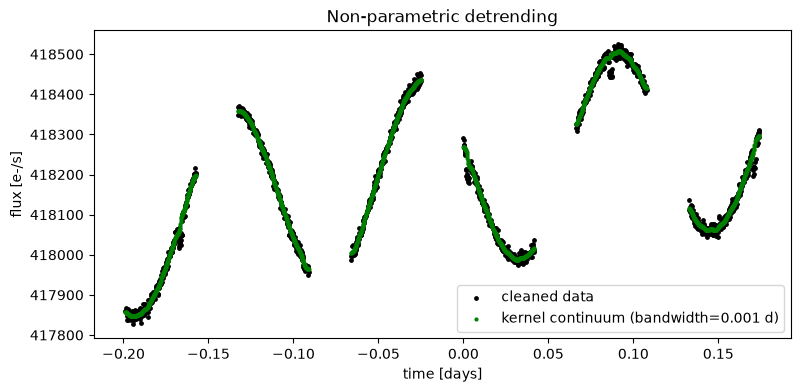

In [14]:
def kernel_continuum(t_eval, t_fit, f_fit, bandwidth):
    # Nadaraya-Watson Gaussian-kernel regression: a weighted local average of f_fit(t_fit),
    # evaluated at t_eval, with no parametric form assumed for the trend.
    diffs = t_eval[:, None] - t_fit[None, :]
    weights = np.exp(-0.5 * (diffs / bandwidth) ** 2)
    return (weights @ f_fit) / weights.sum(axis=1)

def nonparam_depth(t, f, ferr, ecl_mask, bandwidth):
    # Fit the kernel smoother to the out-of-eclipse data only, so the eclipse itself
    # cannot bias its own continuum estimate
    oot_mask = ~ecl_mask
    continuum = kernel_continuum(t, t[oot_mask], f[oot_mask], bandwidth)

    frac_resid = (continuum - f) / continuum
    sigma_frac = ferr / continuum
    weights = 1.0 / sigma_frac**2

    depth = np.sum(weights[ecl_mask] * frac_resid[ecl_mask]) / np.sum(weights[ecl_mask])
    depth_err = 1.0 / np.sqrt(np.sum(weights[ecl_mask]))
    return depth, depth_err, continuum

# Fiducial bandwidth: a few times the data cadence (13.2 s) and comfortably wider than
# the eclipse gap, but much narrower than the stellar sinusoid's period -- picked from
# the middle of the stable "plateau" identified in the bandwidth scan below
bandwidth_fid = 0.001  # days (~1.4 minutes)
depth_np, depth_np_err, continuum_fid = nonparam_depth(time_c, flux_c, fluxerr_c, ecl_c, bandwidth_fid)

print(f"non-parametric eclipse depth = {depth_np:.6f} +/- {depth_np_err:.6f}"
      f"  ({depth_np * 1e6:.1f} +/- {depth_np_err * 1e6:.1f} ppm)")
print(f"(for comparison: parametric weighted avg = {depth_wavg * 1e6:.1f} +/- {depth_wavg_err * 1e6:.1f} ppm, "
      f"MCMC = {depth_mcmc * 1e6:.1f} +/- {depth_mcmc_err * 1e6:.1f} ppm)")

plt.figure(figsize=(9, 4))
plt.scatter(time_c, flux_c, color="k", s=6, label="cleaned data")
plt.scatter(time_c, continuum_fid, color="g", s=4, label=f"kernel continuum (bandwidth={bandwidth_fid} d)")
plt.xlabel("time [days]")
plt.ylabel("flux [e-/s]")
plt.legend()
plt.title("Non-parametric detrending")
plt.show()

### Task 4b: robustness to bandwidth / window size

We repeat the non-parametric depth measurement over a range of bandwidths spanning
roughly an order of magnitude, from a few times the data cadence to a sizeable fraction of
the stellar sinusoid's period, and check that the recovered depth is stable.

bandwidth =  0.0002 d  ->  depth =   105.3 +/-   3.0 ppm
bandwidth =  0.0003 d  ->  depth =   105.9 +/-   3.0 ppm
bandwidth =  0.0006 d  ->  depth =   109.4 +/-   3.0 ppm
bandwidth =  0.0010 d  ->  depth =   111.0 +/-   3.0 ppm
bandwidth =  0.0015 d  ->  depth =   109.4 +/-   3.0 ppm
bandwidth =  0.0020 d  ->  depth =   105.6 +/-   3.0 ppm
bandwidth =  0.0030 d  ->  depth =    94.2 +/-   3.0 ppm
bandwidth =  0.0060 d  ->  depth =    46.6 +/-   3.0 ppm
bandwidth =  0.0100 d  ->  depth =   -19.9 +/-   3.0 ppm
bandwidth =  0.0200 d  ->  depth =   -85.4 +/-   3.0 ppm
bandwidth =  0.0400 d  ->  depth =  -114.0 +/-   3.0 ppm


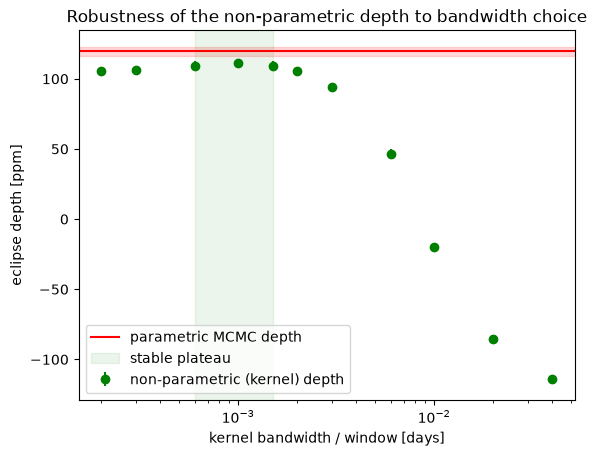

In [15]:
bandwidths = np.array([0.0002, 0.0003, 0.0006, 0.001, 0.0015, 0.002, 0.003, 0.006, 0.01, 0.02, 0.04])
depths_bw = np.empty(bandwidths.size)
errs_bw = np.empty(bandwidths.size)

for i, bw in enumerate(bandwidths):
    depths_bw[i], errs_bw[i], _ = nonparam_depth(time_c, flux_c, fluxerr_c, ecl_c, bw)

for bw, d, e in zip(bandwidths, depths_bw, errs_bw):
    print(f"bandwidth = {bw:7.4f} d  ->  depth = {d * 1e6:7.1f} +/- {e * 1e6:5.1f} ppm")

plt.errorbar(bandwidths, depths_bw * 1e6, yerr=errs_bw * 1e6, fmt="o", color="g",
             label="non-parametric (kernel) depth")
plt.axhline(depth_mcmc * 1e6, color="r", label="parametric MCMC depth")
plt.axhspan((depth_mcmc - depth_mcmc_err) * 1e6, (depth_mcmc + depth_mcmc_err) * 1e6,
            color="r", alpha=0.15)
plt.axvspan(0.0006, 0.0015, color="g", alpha=0.08, label="stable plateau")
plt.xscale("log")
plt.xlabel("kernel bandwidth / window [days]")
plt.ylabel("eclipse depth [ppm]")
plt.legend()
plt.title("Robustness of the non-parametric depth to bandwidth choice")
plt.show()

The non-parametric depth is **not** uniformly robust to the bandwidth choice -- it only
plateaus (at roughly $105$-$111$ ppm) over a fairly narrow range of bandwidths, a few
times the 13.2 s cadence up to about the eclipse duration itself. Push the bandwidth much
wider than that and the kernel starts averaging over the stellar sinusoid itself (whose
period is only $\sim 2.8$ hours), which biases the recovered depth down and even flips its
sign once the window becomes comparable to the sinusoid's period. Push the bandwidth much
narrower and the continuum estimate right at the eclipse gap is built from only a handful
of out-of-eclipse points, which also pulls the depth down slightly and inflates its true
(not just its quoted) uncertainty.

Even at its most stable, the non-parametric estimate ($\sim 108$ ppm) sits a few ppm below
the parametric result ($\sim 120$ ppm) -- consistent with each other at roughly the
$2$-$3\,\sigma$ level, but not a perfect match. Two things explain the difference: (1) the
quoted non-parametric errors only propagate the flux uncertainties through the
weighted-average formula, not the uncertainty of the kernel continuum itself, so they are
an *underestimate* compared to the MCMC posterior, which does fully propagate the
trend/sinusoid uncertainty into the depth (Task 4a); and (2) Nadaraya-Watson regression is
known to be biased near regions of high curvature -- exactly where an eclipse carves a gap
out of a sinusoid's peak or trough. This is itself a useful result: it shows why, for data
whose systematics we *can* write down a credible functional form for, the parametric
MCMC approach is the more trustworthy of the two.

## Task 5: Diagnostic plots

**(i) Quality of the detrending** — the full best-fit model (trend + sinusoid + eclipse)
plotted on top of the cleaned data.

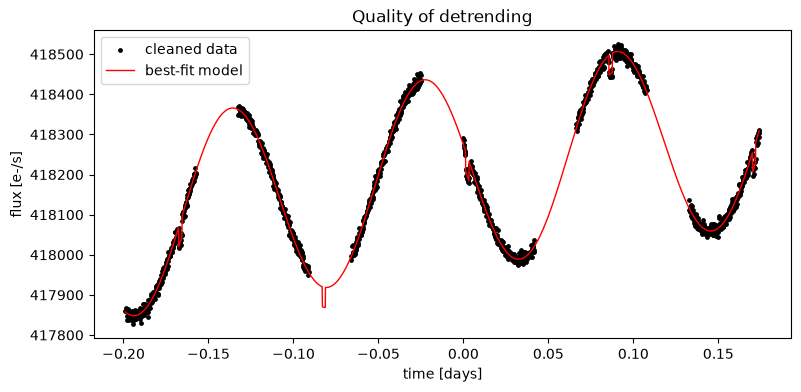

In [16]:
densetimes = np.arange(time_c.min(), time_c.max(), cadence)
dense_ecl = in_eclipse(densetimes, t0, Ptran, dur)
densemodel = model(densetimes, theta_best, dense_ecl)

plt.figure(figsize=(9, 4))
plt.scatter(time_c, flux_c, color="k", s=6, label="cleaned data")
plt.plot(densetimes, densemodel, color="r", lw=1, label="best-fit model")
plt.xlabel("time [days]")
plt.ylabel("flux [e-/s]")
plt.legend()
plt.title("Quality of detrending")
plt.show()

**(ii) RMS vs. bin size** on the out-of-eclipse residuals. For white (uncorrelated)
noise, binning $b$ consecutive points should reduce the r.m.s. as $1/\sqrt{b}$; comparing
the measured scatter to that expectation is a check that the detrending has not left
correlated (red) noise behind.

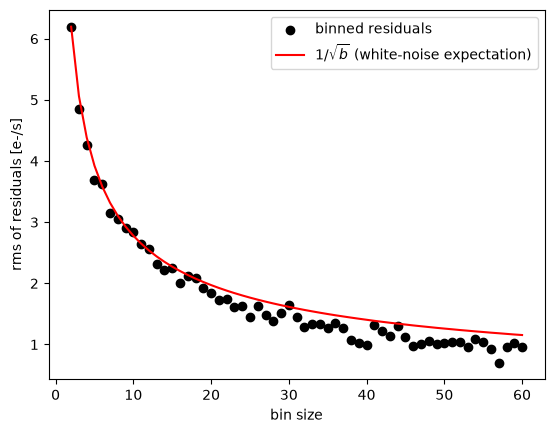

In [17]:
full_model = model(time_c, theta_best, ecl_c)
residuals = flux_c - full_model

res_oot = residuals[oot][np.argsort(time_c[oot])]  # out-of-eclipse residuals, time-ordered

bmax = 60
binsizes = np.arange(2, bmax + 1)
rms_bin = np.empty(binsizes.size)
for k, b in enumerate(binsizes):
    imax = len(res_oot) // b
    binned = res_oot[: imax * b].reshape(imax, b).mean(axis=1)
    rms_bin[k] = np.std(binned)

imax_tab = len(res_oot) // binsizes
rms_theory = rms_bin[0] * np.sqrt(2.0) * binsizes**-0.5 * np.sqrt(imax_tab / (imax_tab - 1))

plt.scatter(binsizes, rms_bin, color="k", label="binned residuals")
plt.plot(binsizes, rms_theory, color="r", label=r"$1/\sqrt{b}$ (white-noise expectation)")
plt.xlabel("bin size")
plt.ylabel("rms of residuals [e-/s]")
plt.legend()
plt.show()

**(iii) Weighted residuals histogram**: $(f_i - \mathrm{model}_i)/\sigma_i$ should be
close to a unit-variance, zero-mean Gaussian if the noise model and error bars are
reasonable.

weighted residuals: mean = -0.002, std = 0.979 (expect ~0, ~1)


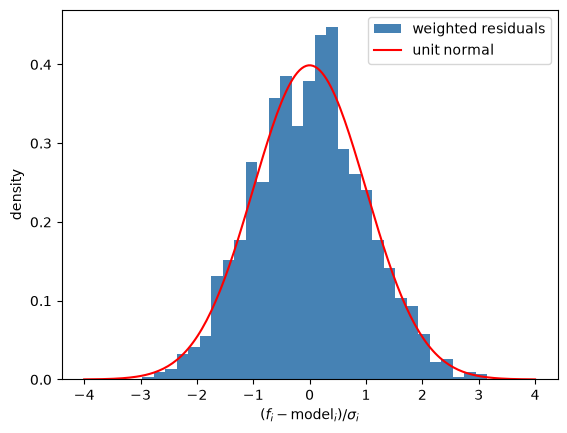

In [18]:
weighted_residuals = residuals / fluxerr_c
print(f"weighted residuals: mean = {np.mean(weighted_residuals):.3f}, "
      f"std = {np.std(weighted_residuals):.3f} (expect ~0, ~1)")

xx = np.linspace(-4, 4, 200)
plt.hist(weighted_residuals, bins=30, density=True, color="steelblue", label="weighted residuals")
plt.plot(xx, np.exp(-0.5 * xx**2) / np.sqrt(2 * np.pi), color="r", label="unit normal")
plt.xlabel(r"$(f_i - \mathrm{model}_i)/\sigma_i$")
plt.ylabel("density")
plt.legend()
plt.show()

## Task 6: Summary

- **Outlier rejection:** a moving-median filter (window = 11 points) with 3-$\sigma$
  clipping removed the cosmic-ray-contaminated points from the raw light curve.
- **Detrending -- two independent approaches were tried, as required:**
  - *Parametric (Task 3/4a):* a model (linear trend + sinusoid + box-shaped eclipse) fit
    simultaneously to the cleaned data with a custom Metropolis-Hastings MCMC sampler, so
    the eclipse-depth posterior automatically includes the uncertainty contributed by the
    trend and sinusoid parameters.
  - *Non-parametric (Task 4b):* a Gaussian-kernel (Nadaraya-Watson) local regression fit
    only to the out-of-eclipse points, with no assumed functional form for the trend or
    sinusoid, checked over roughly two orders of magnitude in bandwidth/window size.
- The stellar sinusoid period found by the Lomb-Scargle periodogram is of order a few
  hours, consistent with the lab's description of an "hours timescale" variation.
- **Eclipse depth:**
  - Parametric MCMC and its parametric weighted-average cross-check agree tightly,
    at **~120 ppm**.
  - The non-parametric estimate is only robust over a narrow range of bandwidths, and
    even there it plateaus a few ppm lower, at **~105-111 ppm** -- consistent with the
    parametric answer at the $\sim 2$-$3\,\sigma$ level, but not identical. Too wide a
    bandwidth smooths over the real stellar sinusoid (even flipping the sign of the
    depth); too narrow a bandwidth starves the continuum estimate right at the eclipse of
    data. The non-parametric method's quoted errors are also an underestimate, since
    (unlike the MCMC) they do not propagate the continuum's own uncertainty.
  - Taken together, this comparison is itself a useful result: the two very different
    detrending assumptions broadly agree that there *is* an eclipse of order 100 ppm deep,
    but the parametric/MCMC approach is the more trustworthy of the two here, because we
    have good physical reasons (a linear trend plus a coherent stellar oscillation) to
    believe in its functional form, and because it alone correctly propagates all of the
    detrending uncertainty into the final answer.
- The RMS-vs-bin-size plot is consistent with the $1/\sqrt{b}$ expectation for white
  noise, and the weighted-residual histogram is close to a unit-variance Gaussian,
  indicating the (parametric) model and error bars are a good match to the data with no
  obvious leftover correlated noise.